In [15]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import os

In [16]:
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.13.0
GPU Available: []


In [17]:
dataset_path = r"C:\Users\Hp\Desktop\images_project"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=16
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=16
)

class_names = train_ds.class_names
print("Classes:", class_names)

val_size = int(0.5 * len(val_test_ds))
val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)


AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 600 files belonging to 3 classes.
Using 420 files for training.
Found 600 files belonging to 3 classes.
Using 180 files for validation.
Classes: ['dangerimages', 'isolatedimages', 'safeimages']


In [18]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

In [19]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation='softmax')
])

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [21]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
27/27 [==============================] - 137s 4s/step - loss: 1.3419 - accuracy: 0.3929 - val_loss: 1.2882 - val_accuracy: 0.3229
Epoch 2/20
27/27 [==============================] - 41s 1s/step - loss: 1.2134 - accuracy: 0.4714 - val_loss: 1.0424 - val_accuracy: 0.4479
Epoch 3/20
27/27 [==============================] - 58s 2s/step - loss: 1.0083 - accuracy: 0.5333 - val_loss: 1.0903 - val_accuracy: 0.4583
Epoch 4/20
27/27 [==============================] - 66s 2s/step - loss: 0.8777 - accuracy: 0.6333 - val_loss: 0.9385 - val_accuracy: 0.6250
Epoch 5/20
27/27 [==============================] - 82s 3s/step - loss: 0.8102 - accuracy: 0.6690 - val_loss: 0.8578 - val_accuracy: 0.6042
Epoch 6/20
27/27 [==============================] - 97s 3s/step - loss: 0.8153 - accuracy: 0.6524 - val_loss: 0.7968 - val_accuracy: 0.6771
Epoch 7/20
27/27 [==============================] - 68s 2s/step - loss: 0.7278 - accuracy: 0.6476 - val_loss: 0.7220 - val_accuracy: 0.7083
Epoch 8/20
27/27 [=

In [22]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)

6/6 [==============================] - 21s 1s/step - loss: 0.6022 - accuracy: 0.7381
Test Accuracy: 0.738095223903656


In [23]:
model.save("survillence.keras")

1/1 [==============================] - 18s 18s/step


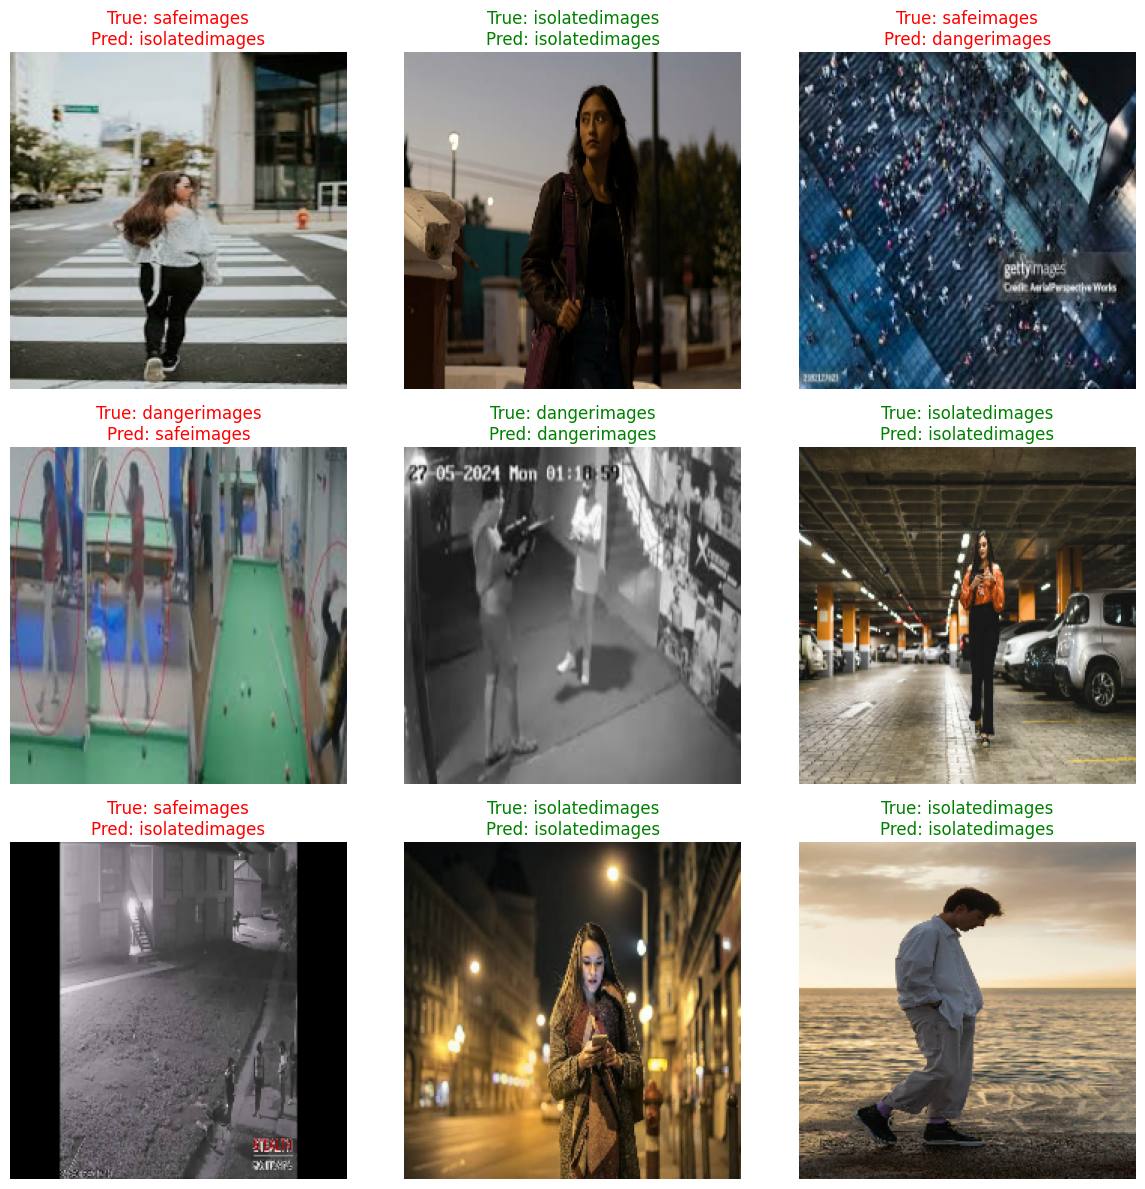

In [24]:
plt.figure(figsize=(12,12))

batch = next(iter(test_ds))
images, labels = batch

predictions = model.predict(images)
predicted_labels = np.argmax(predictions, axis=1)

for i in range(9):
    plt.subplot(3,3,i+1)
    img = images[i].numpy().astype("uint8")

    plt.imshow(img)

    true_label = class_names[labels[i]]
    pred_label = class_names[predicted_labels[i]]

    color = "green" if true_label == pred_label else "red"

    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
    plt.axis("off")

plt.tight_layout()

In [25]:
y_true = []
y_pred = []
y_score = []

for images, labels in test_ds:
    preds = model.predict(images)
    pred_labels = np.argmax(preds, axis=1)
    
    y_true.extend(labels.numpy())
    y_pred.extend(pred_labels)
    y_score.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_score = np.array(y_score)


1/1 [==============================] - 1s 578ms/step


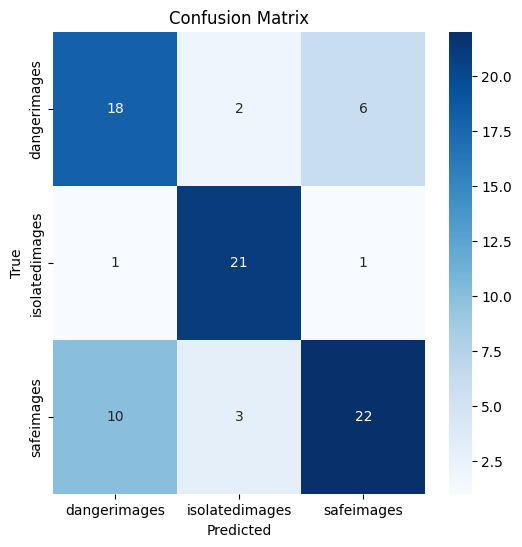

In [26]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


Classification Report:

                precision    recall  f1-score   support

  dangerimages       0.62      0.69      0.65        26
isolatedimages       0.81      0.91      0.86        23
    safeimages       0.76      0.63      0.69        35

      accuracy                           0.73        84
     macro avg       0.73      0.74      0.73        84
  weighted avg       0.73      0.73      0.72        84



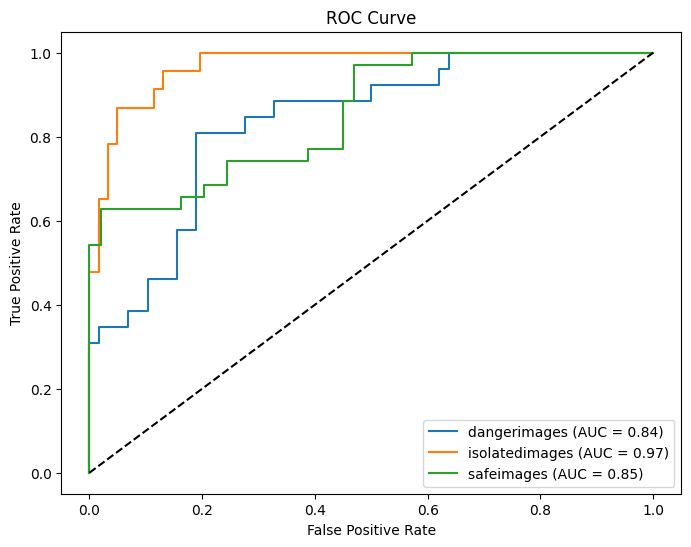

In [27]:
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# ============================================
# 5️⃣ ROC / AUC (optional)
# ============================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_true_bin = label_binarize(y_true, classes=range(len(class_names)))

plt.figure(figsize=(8,6))
for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.2f})')

plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()